# 03 — ANN Improvement and Final Evaluation

This notebook compares the saved baseline ANN with a regularized ANN. It applies the generalization techniques covered in Lab 3: L2 regularization, Dropout, Early Stopping, and learning-rate reduction.

Models are compared using validation data. The test set is loaded only after selecting a model, then used once for final evaluation. Because the classes are imbalanced, macro-averaged F1-score is reported alongside accuracy.

## 1. Requirements

Run this notebook with the same Python environment and project folder used for Notebooks 01 and 02. Required packages are TensorFlow, NumPy, pandas, SciPy, scikit-learn, and Matplotlib.

In [1]:
from IPython.display import display
from pathlib import Path
import json
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import load_npz
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42
BATCH_SIZE = 256
MAX_EPOCHS = 15
NUM_CLASSES = 3
LABEL_NAMES = ["Negative", "Neutral", "Positive"]

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

cwd = Path.cwd().resolve()
project_candidates = [cwd, *cwd.parents]
project_dir = next(
    (
        path for path in project_candidates
        if (path / "data" / "processed" / "X_train.npz").exists()
    ),
    None,
)

if project_dir is None:
    raise FileNotFoundError(
        "Could not find data/processed/X_train.npz. "
        "Run Notebook 01 first and open this notebook from the project folder."
    )

processed_dir = project_dir / "data" / "processed"
models_dir = project_dir / "models"
results_dir = project_dir / "results"
models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

baseline_path = models_dir / "baseline_ann.keras"
if not baseline_path.exists():
    raise FileNotFoundError(
        "The baseline model was not found. Run Notebook 02 and save baseline_ann.keras first."
    )

print("Project folder:", project_dir)
print("Baseline model:", baseline_path)

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Project folder: E:\ANN\ANN_01
Baseline model: E:\ANN\ANN_01\models\baseline_ann.keras


## 2. Load Training and Validation Data

The feature matrices remain sparse on disk. Each mini-batch is converted to a dense array only when it is requested, avoiding a full dense copy of the dataset.

In [2]:
train_df = pd.read_csv(processed_dir / "train.csv")
validation_df = pd.read_csv(processed_dir / "validation.csv")

X_train = load_npz(processed_dir / "X_train.npz").tocsr()
X_validation = load_npz(processed_dir / "X_validation.npz").tocsr()
y_train = train_df["label"].to_numpy(dtype=np.int64)
y_validation = validation_df["label"].to_numpy(dtype=np.int64)

if X_train.shape[0] != len(y_train):
    raise ValueError("Training feature rows and labels do not match.")
if X_validation.shape[0] != len(y_validation):
    raise ValueError("Validation feature rows and labels do not match.")
if X_train.shape[1] != X_validation.shape[1]:
    raise ValueError("Training and validation feature dimensions do not match.")

INPUT_DIM = X_train.shape[1]
print("Training matrix:", X_train.shape)
print("Validation matrix:", X_validation.shape)
print("Input features:", INPUT_DIM)
print("Training labels:", len(y_train))
print("Validation labels:", len(y_validation))

print("Training class distribution:")
display(
    train_df["label"]
    .map(dict(enumerate(LABEL_NAMES)))
    .value_counts()
    .reindex(LABEL_NAMES, fill_value=0)
    .to_frame("count")
)

Training matrix: (319582, 8000)
Validation matrix: (39948, 8000)
Input features: 8000
Training labels: 319582
Validation labels: 39948
Training class distribution:


,count
label,
Negative,41690
Neutral,63551
Positive,214341


## 3. Create Repeating Mini-Batch Datasets

The datasets repeat so that each training epoch receives the specified number of batches. Training batches are shuffled; validation batches remain in a fixed order.

In [3]:
def make_dataset(features, labels, batch_size, shuffle=False):
    labels = np.asarray(labels, dtype=np.int64)
    number_of_samples = features.shape[0]
    epoch_counter = {"value": 0}

    def batch_generator():
        if shuffle:
            rng = np.random.default_rng(SEED + epoch_counter["value"])
            indices = rng.permutation(number_of_samples)
            epoch_counter["value"] += 1
        else:
            indices = np.arange(number_of_samples)

        for start in range(0, number_of_samples, batch_size):
            batch_indices = indices[start:start + batch_size]
            batch_features = features[batch_indices].toarray().astype(np.float32, copy=False)
            yield batch_features, labels[batch_indices]

    dataset = tf.data.Dataset.from_generator(
        batch_generator,
        output_signature=(
            tf.TensorSpec(shape=(None, features.shape[1]), dtype=tf.float32),
            tf.TensorSpec(shape=(None,), dtype=tf.int64),
        ),
    )
    return dataset.repeat().prefetch(1)

train_dataset = make_dataset(X_train, y_train, BATCH_SIZE, shuffle=True)
validation_dataset = make_dataset(X_validation, y_validation, BATCH_SIZE)

train_steps = math.ceil(len(y_train) / BATCH_SIZE)
validation_steps = math.ceil(len(y_validation) / BATCH_SIZE)

print("Batch size:", BATCH_SIZE)
print("Training steps per epoch:", train_steps)
print("Validation steps:", validation_steps)

Batch size: 256
Training steps per epoch: 1249
Validation steps: 157


## 4. Load and Score the Baseline

The baseline is scored on validation data so it can be compared fairly with the regularized model. The test set is not used here.

In [4]:
baseline_model = keras.models.load_model(baseline_path)

baseline_val_loss, baseline_val_accuracy = baseline_model.evaluate(
    validation_dataset,
    steps=validation_steps,
    verbose=1,
)
baseline_val_probabilities = baseline_model.predict(
    validation_dataset,
    steps=validation_steps,
    verbose=0,
)
baseline_val_predictions = np.argmax(baseline_val_probabilities, axis=1)

baseline_metrics = {
    "validation_loss": float(baseline_val_loss),
    "validation_accuracy": float(accuracy_score(y_validation, baseline_val_predictions)),
    "validation_macro_f1": float(
        f1_score(y_validation, baseline_val_predictions, average="macro", zero_division=0)
    ),
}

print("Baseline validation metrics:")
display(pd.DataFrame([baseline_metrics], index=["Baseline ANN"]).round(4))

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8422 - loss: 1.3262
Baseline validation metrics:


,validation_loss,validation_accuracy,validation_macro_f1
Baseline ANN,1.3262,0.8422,0.7684


## 5. Build the Regularized ANN

The improved model keeps the baseline network width for a fair comparison. L2 regularization discourages large weights, while Dropout randomly deactivates some layer outputs during training.

In [5]:
L2_STRENGTH = 1e-4
DROPOUT_RATE = 0.30

improved_model = keras.Sequential(
    [
        keras.Input(shape=(INPUT_DIM,), name="bag_of_words_features"),
        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_STRENGTH),
            name="hidden_1",
        ),
        layers.Dropout(DROPOUT_RATE, name="dropout_1"),
        layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_STRENGTH),
            name="hidden_2",
        ),
        layers.Dropout(DROPOUT_RATE, name="dropout_2"),
        layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities"),
    ],
    name="regularized_ann",
)

improved_model.summary()

Model: "regularized_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 128)            │     1,024,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,032,579 (3.94 MB)

 Trainable params: 1,032,579 (3.94 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the Regularized ANN

Adam updates the model parameters using gradients computed by backpropagation. Sparse categorical cross-entropy is appropriate for integer-encoded class labels.

In [6]:
improved_model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

## 7. Train with Callbacks

Early Stopping monitors validation loss and restores the weights from the best epoch. ReduceLROnPlateau lowers the learning rate if validation loss stops improving.

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

improved_history = improved_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=MAX_EPOCHS,
    steps_per_epoch=train_steps,
    validation_steps=validation_steps,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/15


e:\ANN\ANN_01\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1249/1249 ━━━━━━━━━━━━━━━━━━━━ 31s 23ms/step - accuracy: 0.8544 - loss: 0.4320 - val_accuracy: 0.8665 - val_loss: 0.3969 - learning_rate: 0.0010
Epoch 2/15
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.8747 - loss: 0.3922 - val_accuracy: 0.8685 - val_loss: 0.4023 - learning_rate: 0.0010
Epoch 3/15
1247/1249 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8798 - loss: 0.3894
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 32s 26ms/step - accuracy: 0.8798 - loss: 0.3894 - val_accuracy: 0.8694 - val_loss: 0.4094 - learning_rate: 0.0010
Epoch 4/15
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 32s 26ms/step - accuracy: 0.8943 - loss: 0.3537 - val_accuracy: 0.8687 - val_loss: 0.4060 - learning_rate: 5.0000e-04
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


## 8. Review Learning Curves

Compare training and validation curves. A smaller gap and a stable validation loss indicate better generalization than a model that continues improving only on training data.

,accuracy,loss,val_accuracy,val_loss,learning_rate
epoch,,,,,
1,0.8544,0.4320,0.8665,0.3969,0.0010
2,0.8747,0.3922,0.8685,0.4023,0.0010
3,0.8798,0.3894,0.8694,0.4094,0.0010
4,0.8943,0.3537,0.8687,0.4060,0.0005


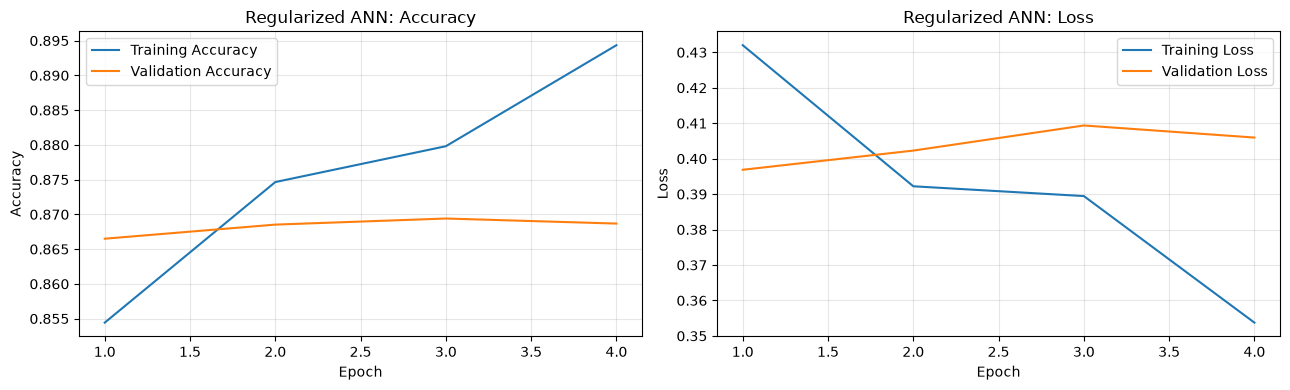

Learning curves saved to: E:\ANN\ANN_01\results\regularized_ann_learning_curves.png


In [8]:
improved_history_df = pd.DataFrame(improved_history.history)
improved_history_df.index = np.arange(1, len(improved_history_df) + 1)
improved_history_df.index.name = "epoch"

display(improved_history_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(improved_history_df.index, improved_history_df["accuracy"], label="Training Accuracy")
axes[0].plot(improved_history_df.index, improved_history_df["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Regularized ANN: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(improved_history_df.index, improved_history_df["loss"], label="Training Loss")
axes[1].plot(improved_history_df.index, improved_history_df["val_loss"], label="Validation Loss")
axes[1].set_title("Regularized ANN: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
improved_curves_path = results_dir / "regularized_ann_learning_curves.png"
plt.savefig(improved_curves_path, dpi=150, bbox_inches="tight")
plt.show()

print("Learning curves saved to:", improved_curves_path)

## 9. Compare Models on Validation Data

Macro F1 gives equal weight to each class, which is useful when class counts differ. The selected model is the one with the higher validation macro F1-score; validation loss breaks ties.

In [9]:
improved_val_loss, improved_val_accuracy = improved_model.evaluate(
    validation_dataset,
    steps=validation_steps,
    verbose=1,
)
improved_val_probabilities = improved_model.predict(
    validation_dataset,
    steps=validation_steps,
    verbose=0,
)
improved_val_predictions = np.argmax(improved_val_probabilities, axis=1)

improved_metrics = {
    "validation_loss": float(improved_val_loss),
    "validation_accuracy": float(accuracy_score(y_validation, improved_val_predictions)),
    "validation_macro_f1": float(
        f1_score(y_validation, improved_val_predictions, average="macro", zero_division=0)
    ),
}

comparison = pd.DataFrame(
    [baseline_metrics, improved_metrics],
    index=["Baseline ANN", "Regularized ANN"],
)
display(comparison.round(4))

comparison.to_csv(results_dir / "validation_model_comparison.csv", encoding="utf-8")
comparison.to_json(
    results_dir / "validation_model_comparison.json",
    orient="index",
    indent=2,
)

if improved_metrics["validation_macro_f1"] > baseline_metrics["validation_macro_f1"]:
    selected_name = "Regularized ANN"
    selected_model = improved_model
    selected_validation_metrics = improved_metrics
else:
    selected_name = "Baseline ANN"
    selected_model = baseline_model
    selected_validation_metrics = baseline_metrics

print("Selected model:", selected_name)
print("Selected validation metrics:", selected_validation_metrics)

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8665 - loss: 0.3969


,validation_loss,validation_accuracy,validation_macro_f1
Baseline ANN,1.3262,0.8422,0.7684
Regularized ANN,0.3969,0.8665,0.7974


Selected model: Regularized ANN
Selected validation metrics: {'validation_loss': 0.3968624174594879, 'validation_accuracy': 0.8665014518874536, 'validation_macro_f1': 0.7973794797364354}


## 10. Save the Selected Model

The model is selected using validation metrics. The untouched test set is not used to choose between models.

In [10]:
selected_model_path = models_dir / "best_sentiment_ann.keras"
selected_model.save(selected_model_path)

selection_summary = {
    "selected_model": selected_name,
    "selection_metric": "validation_macro_f1",
    "validation_metrics": selected_validation_metrics,
    "baseline_validation_metrics": baseline_metrics,
    "regularized_validation_metrics": improved_metrics,
}

selection_path = results_dir / "selected_model_summary.json"
with selection_path.open("w", encoding="utf-8") as file:
    json.dump(selection_summary, file, ensure_ascii=False, indent=2)

print("Selected model saved to:", selected_model_path)
print("Selection summary saved to:", selection_path)

Selected model saved to: E:\ANN\ANN_01\models\best_sentiment_ann.keras
Selection summary saved to: E:\ANN\ANN_01\results\selected_model_summary.json


## 11. Final Evaluation on the Test Set

The test set is loaded only after model selection. These results provide the final estimate of performance on unseen reviews.

In [11]:
test_df = pd.read_csv(processed_dir / "test.csv")
X_test = load_npz(processed_dir / "X_test.npz").tocsr()
y_test = test_df["label"].to_numpy(dtype=np.int64)

if X_test.shape[0] != len(y_test):
    raise ValueError("Test feature rows and labels do not match.")
if X_test.shape[1] != INPUT_DIM:
    raise ValueError("Test feature dimension does not match the training feature dimension.")

test_dataset = make_dataset(X_test, y_test, BATCH_SIZE)
test_steps = math.ceil(len(y_test) / BATCH_SIZE)

test_loss, test_accuracy = selected_model.evaluate(
    test_dataset,
    steps=test_steps,
    verbose=1,
)
test_probabilities = selected_model.predict(
    test_dataset,
    steps=test_steps,
    verbose=0,
)
test_predictions = np.argmax(test_probabilities, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(
    "Test macro F1:",
    f"{f1_score(y_test, test_predictions, average='macro', zero_division=0):.4f}",
)

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8689 - loss: 0.3949
Test loss: 0.3949
Test accuracy: 0.8689
Test macro F1: 0.8012


## 12. Confusion Matrix and Classification Report

The confusion matrix shows correct and incorrect predictions for each class. Precision, recall, and F1-score provide class-specific detail that overall accuracy does not show.

,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,3886,626,700
Actual Neutral,701,5015,2228
Actual Positive,243,740,25809


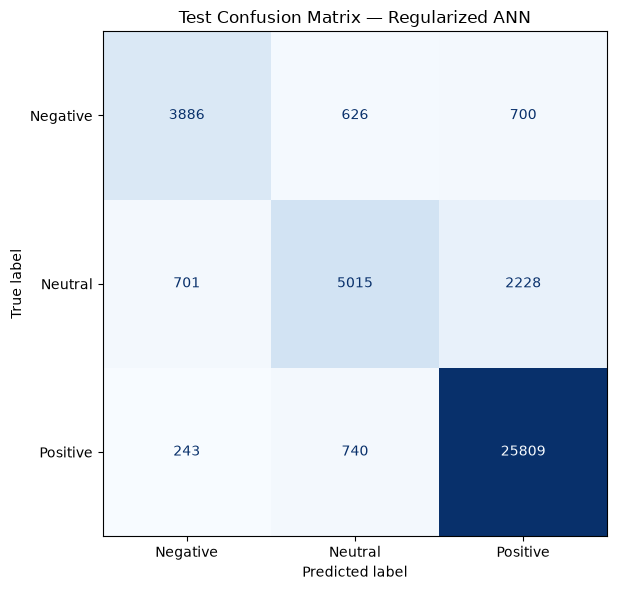

,precision,recall,f1-score,support
Negative,0.8046,0.7456,0.7739,5212.0000
Neutral,0.7859,0.6313,0.7002,7944.0000
Positive,0.8981,0.9633,0.9296,26792.0000
accuracy,0.8689,0.8689,0.8689,0.8689
macro avg,0.8295,0.7801,0.8012,39948.0000
weighted avg,0.8636,0.8689,0.8636,39948.0000


In [12]:
test_confusion_matrix = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(NUM_CLASSES),
)

display(
    pd.DataFrame(
        test_confusion_matrix,
        index=[f"Actual {name}" for name in LABEL_NAMES],
        columns=[f"Predicted {name}" for name in LABEL_NAMES],
    )
)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=LABEL_NAMES,
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
plt.title(f"Test Confusion Matrix — {selected_name}")
plt.tight_layout()

confusion_matrix_path = results_dir / "test_confusion_matrix.png"
plt.savefig(confusion_matrix_path, dpi=150, bbox_inches="tight")
plt.show()

report = classification_report(
    y_test,
    test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))

report_df.to_csv(results_dir / "test_classification_report.csv", encoding="utf-8")
np.savetxt(
    results_dir / "test_confusion_matrix.csv",
    test_confusion_matrix,
    delimiter=",",
    fmt="%d",
)

In [13]:
final_test_metrics = {
    "selected_model": selected_name,
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(
        f1_score(y_test, test_predictions, average="macro", zero_division=0)
    ),
    "test_weighted_f1": float(
        f1_score(y_test, test_predictions, average="weighted", zero_division=0)
    ),
    "test_samples": int(len(y_test)),
    "class_names": LABEL_NAMES,
    "confusion_matrix": test_confusion_matrix.tolist(),
    "classification_report": report,
}

final_metrics_path = results_dir / "final_test_metrics.json"
with final_metrics_path.open("w", encoding="utf-8") as file:
    json.dump(final_test_metrics, file, ensure_ascii=False, indent=2)

print("Final test metrics saved to:", final_metrics_path)
print("Confusion matrix saved to:", confusion_matrix_path)
print("Classification report saved to:", results_dir / "test_classification_report.csv")

Final test metrics saved to: E:\ANN\ANN_01\results\final_test_metrics.json
Confusion matrix saved to: E:\ANN\ANN_01\results\test_confusion_matrix.png
Classification report saved to: E:\ANN\ANN_01\results\test_classification_report.csv


## Outputs

- `models/best_sentiment_ann.keras`: the model selected using validation macro F1-score.
- `results/regularized_ann_learning_curves.png`: training and validation curves for the regularized ANN.
- `results/validation_model_comparison.csv` and `.json`: baseline and regularized model comparison.
- `results/selected_model_summary.json`: selected model and validation metrics.
- `results/final_test_metrics.json`: final test metrics and class-level report.
- `results/test_confusion_matrix.png` and `.csv`: final confusion matrix.
- `results/test_classification_report.csv`: precision, recall, and F1-score by class.

The model was trained on hotel reviews, and labels were derived from star ratings. Results may not transfer directly to other industries or reflect manually annotated sentiment.